# 06 — Weather data

**Does:** downloads daily weather for the 151 weather points (139 unique locations) from the Open-Meteo historical archive, checks it, and takes a first look at how weather relates to the assumptions and to demand.

**Question:** is the downloaded weather complete and believable, and does it show the patterns Part 2 relies on (heat drives demand, monsoon drives wind and hydro)? Then: combine the points into one weather row per state, purpose and day.

**Input:** `data/raw/weather_points.csv`, `data/raw/city_population.csv`, Open-Meteo archive API

**Output:** `data/raw/weather_daily.csv` (one row per point per day); `data/processed/weather_state_daily.csv` (one row per state, purpose and day). Download cache: `data/cache/weather/` (not in git)

**Code:** `src/weather.py`, tested in `tests/test_weather.py` (no internet needed)

**Logged in:** `docs/model_log.md`, Step 13. Weather data by [Open-Meteo.com](https://open-meteo.com/) (CC BY 4.0).

## Design

| Choice | Value | Why |
|---|---|---|
| Source | Open-Meteo historical archive (reanalysis: ERA5-based, ~10–25 km grid) | Free, no key, complete daily history for any point |
| Period | 1 Dec 2019 – 31 Mar 2025 (1,948 days) | One month before the demand data so lags and rainfall totals start on 1 Jan 2020 |
| Day | Indian time (`Asia/Kolkata`) | Same calendar day as the demand data |
| Variables | Max / mean / min temperature, rainfall, solar radiation, cloud cover, wind at 100 m | Decided in Stage 1 Q3 (no humidity for now) |
| Download | One request per unique location, saved to a cache file | Shared places (e.g. a capital for demand and solar) download once; re-runs never download again |
| Safety | Every answer is checked: all days present, no empty values, physical ranges | A broken download should crash, never be saved silently |

The weather is *actual* weather. For forecasting D+1 this is the "perfect weather forecast" case (Step 11, decision 2); the persistence case uses day D's weather instead.

In [1]:
import sys
sys.path.append("../src")

import requests
import pandas as pd
import matplotlib.pyplot as plt

import weather as w
from dispatch import load_demand, load_seasonal_availability

## 1. One point by hand

What the download function does inside, step by step: Jaipur during the May 2024 heatwave. An API is a web address that answers with data (JSON) instead of a web page; the question goes in the URL parameters.

In [2]:
params = {"latitude": 26.912, "longitude": 75.787,
          "start_date": "2024-05-28", "end_date": "2024-05-30",
          "daily": ",".join(w.DAILY_VARIABLES), "timezone": w.TIMEZONE}
response = requests.get(w.ARCHIVE_URL, params=params, timeout=60)
print("status:", response.status_code)          # 200 = OK
payload = response.json()
print("keys:", list(payload.keys()))
print("daily:", {k: v for k, v in payload["daily"].items() if k in ("time", "temperature_2m_max")})

status: 200
keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']
daily: {'time': ['2024-05-28', '2024-05-29', '2024-05-30'], 'temperature_2m_max': [45.5, 46.0, 44.9]}


In [3]:
# 'daily' is a dict of equal-length lists -> a DataFrame directly; parse_daily also checks it
w.parse_daily(payload, "2024-05-28", "2024-05-30")

,Date,temperature_2m_max,temperature_2m_mean,temperature_2m_min,precipitation_sum,shortwave_radiation_sum,cloud_cover_mean,wind_speed_100m_mean
0,2024-05-28,45.5,38.2,30.5,0.0,22.63,7,27.4
1,2024-05-29,46.0,38.6,32.4,0.0,23.93,2,30.1
2,2024-05-30,44.9,37.7,30.9,0.0,24.09,1,27.0


**Prediction check:** Jaipur on 29 May 2024 at **46 °C** max, 2% cloud, no rain: the heatwave is there. (The grid cell is ~10–25 km wide, so a single weather station can read 1–2 °C higher.)

## 2. The points

Purpose
demand    56
hydro     32
solar     46
wind      17
unique locations: 139


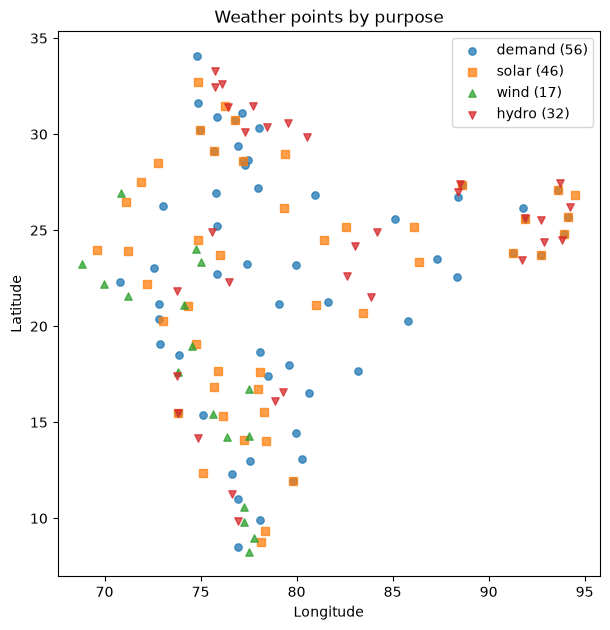

In [4]:
points = w.load_points()
print(points.groupby("Purpose").size().to_string())
print("unique locations:", len(points[["Lat", "Lon"]].drop_duplicates()))

fig, ax = plt.subplots(figsize=(7, 7.5))
for purpose, marker in [("demand", "o"), ("solar", "s"), ("wind", "^"), ("hydro", "v")]:
    p = points[points.Purpose == purpose]
    ax.scatter(p.Lon, p.Lat, marker=marker, s=28, alpha=0.75, label=f"{purpose} ({len(p)})")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Weather points by purpose")
ax.set_aspect("equal"); ax.legend()
plt.show()

## 3. Download everything

`fetch_all` downloads each unique location once (about 3 s each) and caches it; after the first run this cell only reads files.

In [5]:
weather = w.fetch_all(points, verbose=False)
w.check_weather(weather, points)          # raises if any point/day is missing or a value is impossible
print(weather.shape)
weather.describe().T.round(1)

(294148, 9)


,count,mean,min,25%,50%,75%,max,std
Date,294148,2022-07-31 12:00:00,2019-12-01 00:00:00,2021-03-31 18:00:00,2022-07-31 12:00:00,2023-11-30 06:00:00,2025-03-31 00:00:00,NaN
temperature_2m_max,294148.0,29.350266,-7.1,26.0,29.9,33.2,49.8,6.186706
temperature_2m_mean,294148.0,23.923983,-9.8,20.6,25.1,28.0,40.7,6.082422
temperature_2m_min,294148.0,19.296912,-15.6,15.4,20.8,24.3,35.3,6.463884
precipitation_sum,294148.0,4.022804,0.0,0.0,0.0,2.8,419.6,10.988337
shortwave_radiation_sum,294148.0,17.926889,0.67,14.94,18.37,21.51,31.49,4.732328
cloud_cover_mean,294148.0,47.337728,0.0,13.0,44.0,83.0,100.0,35.687034
wind_speed_100m_mean,294148.0,14.527685,1.5,9.0,13.6,18.7,78.3,7.252596


In [6]:
weather.to_csv(w.RAW / "weather_daily.csv", index=False, float_format="%.2f")
print(f"saved {len(weather):,} rows")

saved 294,148 rows


## 4. Does the weather look right?

Four checks against things we know happened.

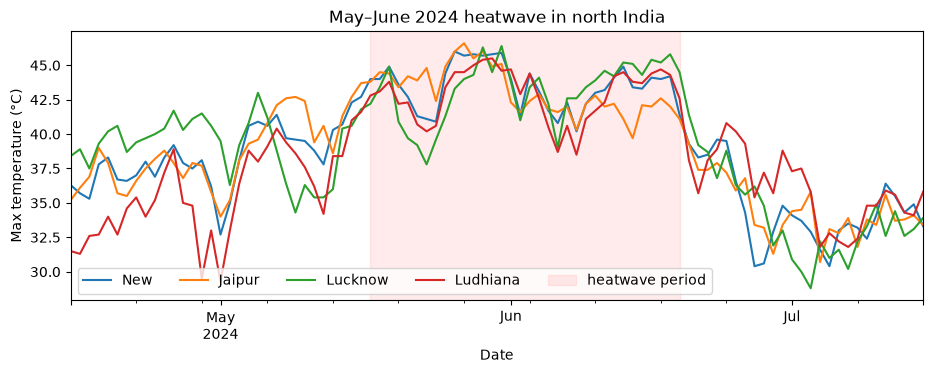

,Point_ID,Date,temperature_2m_max
26963,demand_jodhpur_raj,2024-05-27,48.3
26962,demand_jodhpur_raj,2024-05-26,48.1
28911,demand_kota_raj,2024-05-27,48.0
60081,demand_faridabad_har,2024-05-29,47.4
28912,demand_kota_raj,2024-05-28,47.2


In [7]:
def series(point_id, var):
    return weather[weather.Point_ID == point_id].set_index("Date")[var]

# 4a. May 2024 heatwave in the north
fig, ax = plt.subplots(figsize=(11, 3.5))
for pid in ["demand_new_delhi_del", "demand_jaipur_raj", "demand_lucknow_nr", "demand_ludhiana_pun"]:
    series(pid, "temperature_2m_max").loc["2024-04-15":"2024-07-15"].plot(ax=ax, label=pid.split("_")[1].title())
ax.axvspan("2024-05-17", "2024-06-19", color="red", alpha=0.08, label="heatwave period")
ax.set_ylabel("Max temperature (°C)"); ax.set_title("May–June 2024 heatwave in north India")
ax.legend(ncol=5); plt.show()

hot = weather[weather.Point_ID.str.startswith("demand")].nlargest(5, "temperature_2m_max")
hot[["Point_ID", "Date", "temperature_2m_max"]]

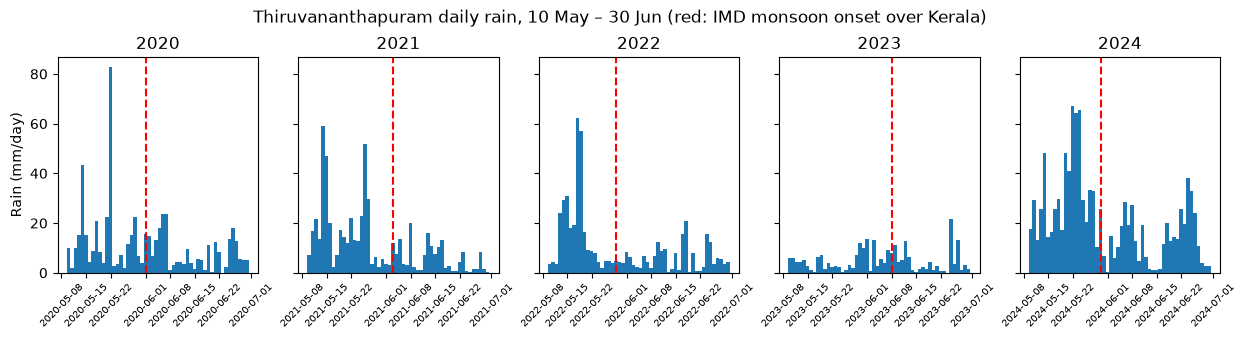

In [8]:
# 4b. Monsoon reaching Kerala: rainfall around 1 June each year (IMD onset dates for comparison)
IMD_ONSET = {2020: "2020-06-01", 2021: "2021-06-03", 2022: "2022-05-29", 2023: "2023-06-08", 2024: "2024-05-30"}
rain = series("demand_thiruvananthapuram_ker", "precipitation_sum")

fig, axes = plt.subplots(1, 5, figsize=(15, 2.8), sharey=True)
for ax, (year, onset) in zip(axes, IMD_ONSET.items()):
    r = rain.loc[f"{year}-05-10":f"{year}-06-30"]
    ax.bar(r.index, r, width=1)
    ax.axvline(pd.Timestamp(onset), color="red", ls="--")
    ax.set_title(str(year)); ax.tick_params(axis="x", labelrotation=45, labelsize=7)
axes[0].set_ylabel("Rain (mm/day)")
fig.suptitle("Thiruvananthapuram daily rain, 10 May – 30 Jun (red: IMD monsoon onset over Kerala)", y=1.05)
plt.show()

### 4c. Seasonal shapes vs the assumed availability factors

Step 10 assumed monthly availability shapes for solar, wind and hydro. The weather now gives an independent view of the same seasons. Each line is normalised to its own yearly average (1.0 = average month), so only the *shape* is compared.

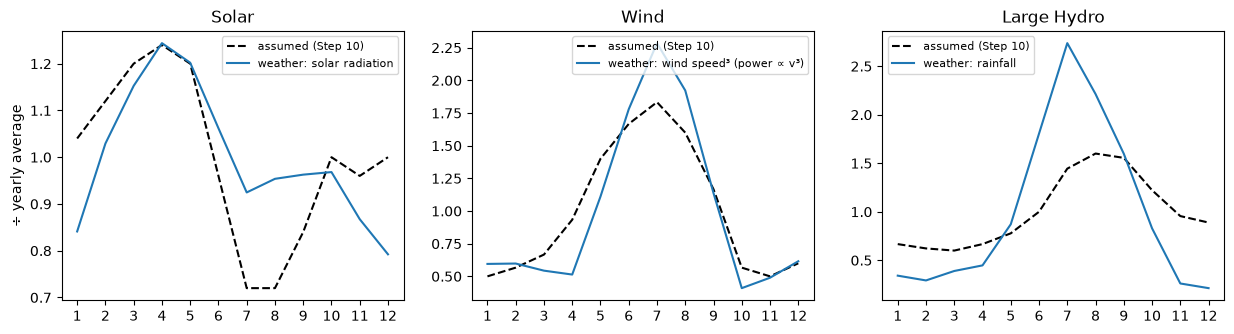

,correlation,weather peak month,assumed peak month
Solar,0.614194,4.0,4.0
Wind,0.944353,7.0,7.0
Large Hydro,0.807971,7.0,8.0


In [9]:
seasonal = load_seasonal_availability()
full_years = weather[weather.Date.between("2020-01-01", "2024-12-31")].copy()
full_years["Month"] = full_years.Date.dt.month
purpose = full_years.Point_ID.str.split("_").str[0]

def monthly_shape(purpose_name, var):
    m = full_years[purpose == purpose_name].groupby("Month")[var].mean()
    return m / m.mean()

compare = {
    "Solar": (monthly_shape("solar", "shortwave_radiation_sum"), "solar radiation"),
    "Wind": (monthly_shape("wind", "wind_speed_100m_mean") ** 3 / (monthly_shape("wind", "wind_speed_100m_mean") ** 3).mean(),
             "wind speed³ (power ∝ v³)"),
    "Large Hydro": (monthly_shape("hydro", "precipitation_sum"), "rainfall"),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
rows = {}
for ax, (fuel, (shape, label)) in zip(axes, compare.items()):
    assumed = seasonal[fuel] / seasonal[fuel].mean()
    ax.plot(assumed.index, assumed, "k--", label="assumed (Step 10)")
    ax.plot(shape.index, shape, label=f"weather: {label}")
    ax.set_title(fuel); ax.set_xticks(range(1, 13)); ax.legend(fontsize=8)
    rows[fuel] = {"correlation": shape.corr(assumed), "weather peak month": shape.idxmax(),
                  "assumed peak month": assumed.idxmax()}
axes[0].set_ylabel("÷ yearly average")
plt.show()
pd.DataFrame(rows).T

### 4d. First look: temperature vs demand

Delhi has a single demand point, so no combining is needed yet. Indian demand typically rises with heat (cooling) and also slightly in the coldest weeks (heating, lighting): a U or hockey-stick shape.

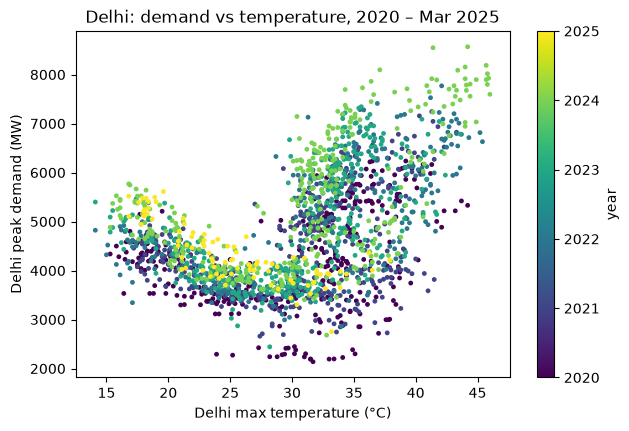

correlation, all days: 0.45
correlation, days above 30 °C: 0.42


In [10]:
demand = load_demand()
delhi = pd.DataFrame({"Tmax": series("demand_new_delhi_del", "temperature_2m_max"),
                      "Demand_MW": demand["Delhi"]}).dropna()

fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(delhi.Tmax, delhi.Demand_MW, c=delhi.index.year, s=6, cmap="viridis")
plt.colorbar(sc, label="year")
ax.set_xlabel("Delhi max temperature (°C)"); ax.set_ylabel("Delhi peak demand (MW)")
ax.set_title("Delhi: demand vs temperature, 2020 – Mar 2025")
plt.show()

print("correlation, all days:", round(delhi.Tmax.corr(delhi.Demand_MW), 2))
print("correlation, days above 30 °C:", round(delhi[delhi.Tmax > 30].Tmax.corr(delhi[delhi.Tmax > 30].Demand_MW), 2))

## 5. Combine points into states

The models need **one value per state per day**, for each purpose. Each (State, Purpose) group is a weighted average of its points:

- **Demand:** weighted by city population. More people → more fans and ACs → that city's weather matters more. Hand example: two cities with 3 M and 1 M people and max temperatures 40 °C and 20 °C → weights 0.75 and 0.25 → state value **0.75 × 40 + 0.25 × 20 = 35 °C** (a simple average would say 30 °C)
- **Solar, wind, hydro:** equal weights. Weighting by plant capacity would be better, but our generator data has one capacity per state and fuel, not per plant
- States with a single point keep that point's values unchanged

The average is taken **day by day**, before any features are made, so each day's state value is a real mix of that day's weather.

This is tested with the hand example above in `tests/test_weather.py`.

In [11]:
population = w.load_population()
weights = w.point_weights(points, population)

multi = weights[(weights.Purpose == "demand") & (weights.Weight < 1)].merge(points[["Point_ID", "Place"]])
multi.pivot_table(index="State", columns=multi.groupby("State").cumcount() + 1,
                  values=["Place", "Weight"], aggfunc="first").sort_index(axis=1, level=1)

,Place,Weight,Place,Weight,Place,Weight
,1,1,2,2,3,3
State,,,,,,
Andhra Pradesh,Visakhapatnam,0.529766,Vijayawada,0.317087,Nellore,0.153147
Gujarat,Ahmedabad,0.492211,Surat,0.394249,Rajkot,0.113540
Haryana,Faridabad,0.703604,Hisar,0.149962,Panipat,0.146434
MP,Indore,0.407670,Bhopal,0.373242,Jabalpur,0.219087
NR UP,Lucknow,0.465525,Ghaziabad,0.272438,Agra,0.262037
Punjab,Ludhiana,0.533043,Amritsar,0.372856,Bathinda,0.094101
Rajasthan,Jaipur,0.599448,Jodhpur,0.203431,Kota,0.197121
SR Karnataka,Bengaluru,0.821327,Hubballi-Dharwad,0.091803,Mysuru,0.086869


In [12]:
state_weather = w.combine_points(weather, points, population)

groups = points.groupby(["State", "Purpose"]).ngroups
n_days = weather.Date.nunique()
assert len(state_weather) == groups * n_days
assert state_weather.notna().all().all()

# a weighted average must lie between the smallest and largest of its points, every day
pt = weather.merge(points[["Point_ID", "State", "Purpose"]])
bounds = pt.groupby(["Date", "State", "Purpose"])["temperature_2m_max"].agg(["min", "max"])
check = state_weather.set_index(["Date", "State", "Purpose"])["temperature_2m_max"]
bounds = bounds.reindex(check.index)                      # same row order as check
assert ((check >= bounds["min"] - 1e-9) & (check <= bounds["max"] + 1e-9)).all()

# single-point groups are unchanged (Delhi demand = the New Delhi point)
assert (state_weather.query("State == 'Delhi' and Purpose == 'demand'").set_index("Date")["temperature_2m_max"]
        .equals(series("demand_new_delhi_del", "temperature_2m_max")))

print(f"{groups} state-purpose groups x {n_days} days = {len(state_weather):,} rows")
state_weather.groupby("Purpose").State.nunique().rename("states")

101 state-purpose groups x 1948 days = 196,748 rows


Purpose
demand    32
hydro     28
solar     32
wind       9
Name: states, dtype: int64

In [13]:
# where does population weighting change the answer? mean |weighted - simple average| of demand max temperature
simple = pt[pt.Purpose == "demand"].groupby(["Date", "State"])["temperature_2m_max"].mean()
weighted = state_weather[state_weather.Purpose == "demand"].set_index(["Date", "State"])["temperature_2m_max"]
diff = (weighted - simple).abs().groupby(level="State").mean()
diff[diff > 0].sort_values(ascending=False).round(2).rename("mean |weighted − simple| (°C)").to_frame()

,mean |weighted − simple| (°C)
State,
Tamil Nadu,1.01
WR Maharashtra,0.95
West Bengal,0.81
SR Karnataka,0.76
Telangana,0.72
Andhra Pradesh,0.45
Rajasthan,0.39
Punjab,0.36
Haryana,0.33


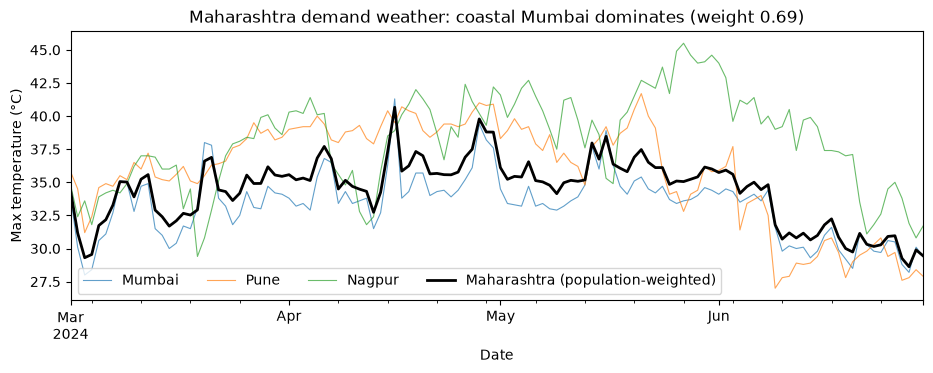

In [14]:
fig, ax = plt.subplots(figsize=(11, 3.5))
window = slice("2024-03-01", "2024-06-30")
for pid in ["demand_mumbai_wr", "demand_pune_wr", "demand_nagpur_wr"]:
    series(pid, "temperature_2m_max").loc[window].plot(ax=ax, lw=0.8, alpha=0.7, label=pid.split("_")[1].title())
mh = state_weather.query("State == 'WR Maharashtra' and Purpose == 'demand'").set_index("Date")["temperature_2m_max"]
mh.loc[window].plot(ax=ax, color="black", lw=2, label="Maharashtra (population-weighted)")
ax.set_ylabel("Max temperature (°C)"); ax.legend(ncol=4)
ax.set_title("Maharashtra demand weather: coastal Mumbai dominates (weight 0.69)")
plt.show()

In [15]:
out = w.PROCESSED / "weather_state_daily.csv"
state_weather.to_csv(out, index=False, float_format="%.2f")
print(f"saved {len(state_weather):,} rows to {out.name}")

saved 196,748 rows to weather_state_daily.csv


## Conclusions

**Data:** 151 points × 1,948 days = 294,148 rows, no gaps, no empty values, all within physical ranges. Saved as `data/raw/weather_daily.csv` (~20 MB). The free API allows about 100 five-year downloads per hour, so the first full download takes two sittings; the cache makes that harmless.

**Believable?**
- **Heatwave:** the five hottest demand-point days are all 26–29 May 2024 (Jodhpur 48.3 °C, Kota 48.0 °C, Faridabad 47.4 °C), the peak of the record heatwave
- **Monsoon in Kerala:** rain builds through late May and June every year, but pre-monsoon showers start in mid-May, so a simple "first wet days" rule fires 2–3 weeks before IMD's official onset. Fine for us: we use rainfall amounts, not onset dates. 2023 (late onset, 8 June) is the driest May–June; 2024 the wettest

**Weather vs the assumed seasonal shapes (Step 10):**

| Fuel | Correlation | Peak month (weather / assumed) | What differs |
|---|---|---|---|
| Wind | 0.94 | Jul / Jul | Almost the same shape: the assumption was good |
| Solar | 0.61 | Apr / Apr | Weather radiation dips much **less** in the monsoon (0.92–0.96 of average vs assumed 0.72) and much **more** in winter (0.79–0.84 vs assumed ~1.0): short winter days and haze. The assumed shape overstates winter solar, so winter prices in Part 1 may be too low |
| Hydro (rain) | 0.81 | Jul / Aug | Rain is far more peaked (2.7× average in July vs 1.4–1.6× assumed) and peaks a month earlier. Reservoirs store rain and release it later, so Stage 2 needs a rainfall *running total* (storage), not daily rain |

**Delhi, temperature vs demand:** a U-shape, as expected. Lowest demand at 25–30 °C max (~3,740 MW), rising to ~6,530 MW above 40 °C, and ~4,700–4,850 MW below 20 °C (winter heating and lighting). The straight-line correlation is only 0.45 *because* the shape is curved: a linear model needs features that bend, such as cooling and heating degree days (Stage 3).

**Combined into states:** 101 state-purpose groups (32 demand, 32 solar, 9 wind, 28 hydro) × 1,948 days = 196,748 rows in `data/processed/weather_state_daily.csv`. Every combined value lies between its points' values. The largest city carries 41% (MP, Indore) to 88% (Telangana, Hyderabad) of its state's demand weight. Weighting changes the state's max temperature by about 1 °C on an average day in Tamil Nadu and Maharashtra (coastal Chennai and Mumbai dominate, and their weather differs most from the inland cities), and by under 0.2 °C in MP and UP, where the cities have similar weather.

**Next (Stage 2):** turn the solar, wind and hydro weather into daily availability factors, and re-run dispatch with them to make the new "actual" prices.